# 01 · Data understanding, ingestion and preprocessing

**Goal:** turn the raw logger export into one clean, documented, analysis-ready table
(`data/processed/clean.parquet`). All logic lives in `src/load_data.py`; this notebook
runs it step by step and prints the evidence for every decision.

The complete pipeline can also be run with a single command from the repository root:
`python -m src.load_data`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C, load_data as L, results, plotting as P
from src.physics import absolute_humidity, dew_point

P.setup()
pd.set_option("display.width", 160, "display.max_columns", 50)

## 1 · Raw file: schema, size and format

The file is a semicolon-separated InfluxDB export (UTF-8, CRLF line endings) with a
**decimal comma** and the **missing code `-255`**. We read it with `sep=";"` and
`decimal=","`, which makes every measurement column numeric without string hacks.

In [2]:
raw = L.read_raw()
print("shape:", raw.shape)
print("dtypes:", raw.dtypes.value_counts().to_dict())
print("technical columns:", {c: raw[c].unique()[:3].tolist() for c in C.TECHNICAL_COLUMNS})
with open(C.RAW_FILE, "rb") as fh:
    head = fh.read(4000)
print("CRLF line endings:", b"\r\n" in head)
raw.iloc[:3, :8]

shape: (49032, 44)
dtypes: {dtype('float64'): 41, <StringDtype(na_value=nan)>: 2, dtype('int64'): 1}
technical columns: {'result': ['_result'], 'table': [0, 1, 2]}
CRLF line endings: True


,result,table,_time,Luft-Temperatur_AU,Luft-Feuchtigkeit_AU,Absolute-Luft-Feuchtigkeit_AU,Taupunkt_AU,Luft-Temperatur_O1
0,_result,0,2024-01-18T23:00:00Z,-255.0,-255.0,-255.0,-255.0,-255.0
1,_result,1,2024-01-18T23:20:00Z,-255.0,-255.0,-255.0,-255.0,-255.0
2,_result,2,2024-01-18T23:40:00Z,-255.0,-255.0,-255.0,-255.0,-255.0


### Sensor dictionary

Column pattern `<Measure>_<Sensor>`. Measures are renamed to short English prefixes.
Absolute humidity and dew point are *derived* by the logger from temperature and
relative humidity (verified below).

In [3]:
measures = pd.DataFrame([(k, v[0], v[1], v[2]) for k, v in C.MEASURES.items()],
                        columns=["raw name", "short prefix", "unit", "meaning"])
display(measures)
cols = [c for c in raw.columns if c not in C.TECHNICAL_COLUMNS + [C.TIME_COLUMN]]
avail = pd.DataFrame(0, index=list(C.SENSORS), columns=[v[0] for v in C.MEASURES.values()])
for c in cols:
    m, s = c.rsplit("_", 1)
    avail.loc[s, C.MEASURES[m][0]] = 1
sensors = pd.DataFrame(C.SENSORS).T[["client", "level", "has_surface"]].join(avail)
sensors.index.name = "code"
display(sensors)
results.save_table(sensors, "sensor_dictionary")

,raw name,short prefix,unit,meaning
0,Luft-Temperatur,temp,degC,air temperature
1,Luft-Feuchtigkeit,rh,%,relative humidity
2,Oberflächen-Temperatur,surf_temp,degC,surface temperature
3,Absolute-Luft-Feuchtigkeit,abs_hum,g/m3,absolute humidity
4,Taupunkt,dew_point,degC,dew point


,client,level,has_surface,temp,rh,surf_temp,abs_hum,dew_point
code,,,,,,,,
AU,Outside air,outside,False,1,1,0,1,1
O1,Organ,upper,True,1,1,1,1,1
AWn,North exterior wall (lower level),lower,True,1,1,1,1,1
AWs,South exterior wall (lower level),lower,True,1,1,1,1,1
AWo,East exterior wall (lower level),lower,True,1,1,1,1,1
K1,"Art objects, north-west corner",lower,True,1,1,1,1,1
K2,"Art objects, south wall",upper,False,1,1,0,1,1
D1,Attic,attic,False,1,1,0,1,1
Ke1,Basement storage area,basement,False,1,1,0,1,1


### Time axis

`_time` is ISO-8601 in **UTC**. We parse it as UTC, check duplicates and the
20-minute grid, and only at the end convert to **Europe/Berlin** local time, because
daily patterns (heating, services) follow local clock time. Doing all grid checks in
UTC avoids the duplicate / missing hour at the daylight-saving switches.

In [4]:
t = pd.to_datetime(raw[C.TIME_COLUMN], utc=True)
step = t.diff().dropna()
print("first:", t.min(), " last:", t.max(), " rows:", len(t))
print("duplicated timestamps:", t.duplicated().sum())
print("sampling steps:", step.value_counts().to_dict())
print("expected rows on a 20-min grid:", len(pd.date_range(t.min(), t.max(), freq="20min")))
local = t.dt.tz_convert(C.LOCAL_TZ)
print("UTC offsets present in local time:", sorted(local.map(lambda x: x.utcoffset()).astype(str).unique()))

first: 2024-01-18 23:00:00+00:00  last: 2025-11-29 22:40:00+00:00  rows: 49032
duplicated timestamps: 0
sampling steps: {Timedelta('0 days 00:20:00'): 49031}
expected rows on a 20-min grid: 49032


UTC offsets present in local time: ['0 days 01:00:00', '0 days 02:00:00']


## 2 · Missing code and raw value ranges

`-255` is a logger code for "no value". It must become `NaN` *before* any statistic
is computed; otherwise means and minima are meaningless. We also verify that no other
sentinel-like value (e.g. `-999`, `0` blocks) exists.

In [5]:
num = raw[cols]
print("cells equal to -255:", int((num == C.MISSING_CODE).sum().sum()), "of", num.size)
print("values < -100 other than -255:", int(((num < -100) & (num != C.MISSING_CODE)).sum().sum()))
desc = num.replace(C.MISSING_CODE, np.nan).describe().T[["count", "min", "mean", "max"]]
desc.round(2)

cells equal to -255: 575903 of 2010312
values < -100 other than -255: 0


,count,min,mean,max
Luft-Temperatur_AU,48471.0,-2.49,13.38,40.44
Luft-Feuchtigkeit_AU,48471.0,21.13,82.09,105.73
Absolute-Luft-Feuchtigkeit_AU,48471.0,2.54,9.70,27.82
Taupunkt_AU,48471.0,-8.41,9.91,28.47
Luft-Temperatur_O1,48935.0,6.67,14.90,24.80
Luft-Feuchtigkeit_O1,48935.0,30.66,70.28,92.36
Oberflächen-Temperatur_O1,48504.0,4.13,14.24,25.26
Absolute-Luft-Feuchtigkeit_O1,48935.0,3.49,9.23,16.32
Taupunkt_O1,48935.0,-4.01,9.48,19.31
Luft-Temperatur_AWn,8121.0,7.68,13.31,20.89


## 3 · Run the cleaning pipeline

`L.clean()` performs all steps listed in the module docstring and returns the clean
frame, a **change log** (every modification with count and reason) and the longest run
of identical values per column. Nothing is changed silently.

In [6]:
df, clog, longest = L.clean(raw)
print("clean shape:", df.shape, "| index:", df.index.dtype, "| from", df.index.min(), "to", df.index.max())
summary_log = clog[clog.n_values > 0].groupby(["step", "action"])["n_values"].sum().to_frame()
summary_log

clean shape: (48988, 61) | index: datetime64[us, Europe/Berlin] | from 2024-01-19 08:20:00+01:00 to 2025-11-29 17:20:00+01:00


n_values
step         action                                               
drop_columns dropped                                         49032
interpolate  linear, gaps <= 3 readings                       3282
missing_code -255 -> NaN                                    575903
physical_fix clipped to 100 %                                10541
             recomputed at 100 %                             10541
             set to air temperature                          10505
sun_flag     flagged (kept)                                    295
timezone     UTC -> Europe/Berlin                            48988
trim         leading/trailing empty rows removed                44
warmup       first 6 readings after 1 (re)starts -> NaN          8
             first 6 readings after 16 (re)starts -> NaN        96
             first 6 readings after 2 (re)starts -> NaN         32
             first 6 readings after 3 (re)starts -> NaN         35
             first 6 readings after 4 (re)starts -> NaN         24

### 3a · Humidity above 100 % and dew point above air temperature

Only the **outside** sensor reports relative humidity above 100 % (fog, rain, sensor
saturation). Indoor sensors never do. Air cannot hold more than 100 % relative
humidity, so we **clip to 100 %**, set the dew point to the air temperature,
recompute absolute humidity at saturation and keep the flag `flag_rh_clipped_AU`.

In [7]:
r = raw.replace(C.MISSING_CODE, np.nan)
checks = pd.DataFrame({
    s: {"rh > 100 %": int((r[f"Luft-Feuchtigkeit_{s}"] > 100).sum()),
        "max rh": r[f"Luft-Feuchtigkeit_{s}"].max(),
        "dew point > air temp": int((r[f"Taupunkt_{s}"] > r[f"Luft-Temperatur_{s}"]).sum())}
    for s in C.SENSORS}).T
display(checks)
n_rh, n_dp = int(checks.loc["AU", "rh > 100 %"]), int(checks.loc["AU", "dew point > air temp"])
print(f"outside: {n_rh} readings above 100 % (max {checks.loc['AU','max rh']:.1f} %), {n_dp} with dew point > air temp")
print("after cleaning: max rh outside =", df["rh_AU"].max(), "| dew>temp:", int((df.dew_point_AU > df.temp_AU + 0.01).sum()))
results.update(rh_over_100_AU=n_rh, rh_max_AU=checks.loc["AU", "max rh"], dp_over_t_AU=n_dp)

,rh > 100 %,max rh,dew point > air temp
AU,10541.0,105.73,10505.0
O1,0.0,92.36,0.0
AWn,0.0,84.02,0.0
AWs,0.0,84.08,0.0
AWo,0.0,82.91,0.0
K1,0.0,93.16,0.0
K2,0.0,93.03,0.0
D1,0.0,97.15,0.0
Ke1,0.0,94.71,0.0


outside: 10541 readings above 100 % (max 105.7 %), 10505 with dew point > air temp
after cleaning: max rh outside = 100.0 | dew>temp: 0


### 3b · Are derived quantities consistent? (Magnus formula)

If absolute humidity and dew point are computed by the logger from temperature and
relative humidity, we can recompute them and use the same formula later (surface
relative humidity). Differences within ±0.005 mean the logger uses the Magnus
constants 17.62 / 243.12 °C and rounds to two decimals.

In [8]:
rows = []
for s in C.SENSORS:
    T, RH = r[f"Luft-Temperatur_{s}"], r[f"Luft-Feuchtigkeit_{s}"]
    ok = RH <= 100
    rows.append(dict(sensor=s,
                     max_abs_diff_abs_hum=np.nanmax(np.abs(absolute_humidity(T[ok], RH[ok]) - r[f"Absolute-Luft-Feuchtigkeit_{s}"][ok])),
                     max_abs_diff_dew_point=np.nanmax(np.abs(dew_point(T[ok], RH[ok]) - r[f"Taupunkt_{s}"][ok]))))
magnus = pd.DataFrame(rows).set_index("sensor").round(4)
display(magnus)
results.update(magnus_max_diff=float(magnus.max().max()))

,max_abs_diff_abs_hum,max_abs_diff_dew_point
sensor,,
AU,0.005,0.0052
O1,0.005,0.0051
AWn,0.005,0.0051
AWs,0.005,0.0051
AWo,0.005,0.0051
K1,0.005,0.0051
K2,0.005,0.0052
D1,0.005,0.0052
Ke1,0.005,0.0051


**Decision:** derived values are exactly reproducible, so after interpolating
temperature and humidity we *recompute* absolute humidity and dew point instead of
interpolating them separately (keeps the physics consistent).

### 3c · Sensor warm-up after installation and outages

Right after installation (19 Jan 2024) and after long outages several sensors report a
value far from the room and relax exponentially within about an hour. Example: the
organ sensor starts at 24.8 °C and falls to 18.7 °C in one hour, while the church is at
about 10 °C. This is the sensor adapting, not the room. Left in the data it would create
false rapid-change events at the organ.

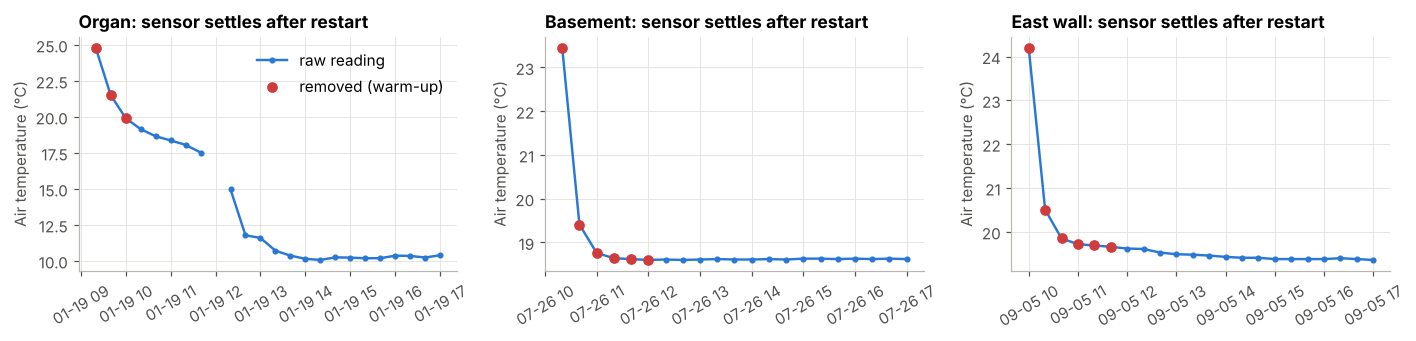

  column  n_values                                      action
 temp_AU        18  first 6 readings after 3 (re)starts -> NaN
 temp_O1         4  first 6 readings after 1 (re)starts -> NaN
temp_AWn        12  first 6 readings after 2 (re)starts -> NaN
temp_AWs        17  first 6 readings after 3 (re)starts -> NaN
temp_AWo        24  first 6 readings after 4 (re)starts -> NaN
 temp_K1        12  first 6 readings after 2 (re)starts -> NaN
 temp_K2         4  first 6 readings after 1 (re)starts -> NaN
 temp_D1        96 first 6 readings after 16 (re)starts -> NaN
temp_Ke1         8  first 6 readings after 2 (re)starts -> NaN


In [9]:
raw_min = L.load_raw_minimal()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (s, start) in zip(axes, [("O1", "2024-01-19 09:00"), ("Ke1", "2024-07-26 09:00"), ("AWo", "2025-09-05 09:00")]):
    t0 = pd.Timestamp(start, tz=C.LOCAL_TZ)
    w = raw_min.loc[t0:t0 + pd.Timedelta("8h"), f"temp_{s}"]
    fl = df.loc[w.index, f"flag_warmup_{s}"]
    ax.plot(w.index, w, color=P.SERIES[0], marker="o", ms=3, label="raw reading")
    ax.plot(w.index[fl], w[fl], "o", color=P.STATUS["high"], ms=6, label="removed (warm-up)")
    ax.set_title(f"{P.name(s)}: sensor settles after restart")
    ax.set_ylabel("Air temperature (°C)")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout(); P.save(fig, "01_warmup.png"); plt.show()
print(clog[clog.step == "warmup"][["column", "n_values", "action"]].to_string(index=False))

**Decision:** after a sensor (re)start following a gap of at least 6 h, the first
6 readings (2 h) are set to `NaN` and flagged (`flag_warmup_*`). This removes
195 readings in total (mostly the patchy attic sensor) and is logged.

### 3d · Stuck sensors

A frozen sensor repeats the same value. We list the longest run of identical values per
column; runs of ≥ 12 h (36 readings) in temperature or humidity would be set to `NaN`.
Runs at exactly 100 % outside humidity are saturation (step 3a), not a frozen sensor.

In [10]:
lr = longest.to_frame()
lr["hours"] = (lr["longest_identical_run"] / 3).round(1)
display(lr.sort_values("longest_identical_run", ascending=False).head(10))
print("columns with a run >= 12 h (excluding derived quantities):",
      [c for c, v in longest.items() if v >= C.STUCK_MIN_RUN and L.measure_of(c) in ("temp", "rh", "surf_temp")])

,longest_identical_run,hours
abs_hum_O1,17,5.7
temp_Ke1,14,4.7
abs_hum_AWs,14,4.7
abs_hum_AWn,13,4.3
abs_hum_Ke1,12,4.0
abs_hum_K1,10,3.3
temp_O1,8,2.7
dew_point_AWs,8,2.7
temp_AWs,8,2.7
abs_hum_K2,8,2.7


columns with a run >= 12 h (excluding derived quantities): []


**Decision:** the longest runs are ≤ 5.3 h and occur in derived absolute humidity (which
is stable at 0.01 g/m³ resolution in a calm building) or the very stable basement. No
sensor is stuck; nothing is removed.

### 3e · Extreme outside temperatures – direct sun on the sensor?

The outside sensor reaches about 40 °C. The daily maximum of air temperature normally
occurs around 14–16 h. If the sensor is hit by the low evening sun on the west tower,
its maximum shifts to the evening and the values exceed realistic air temperatures.

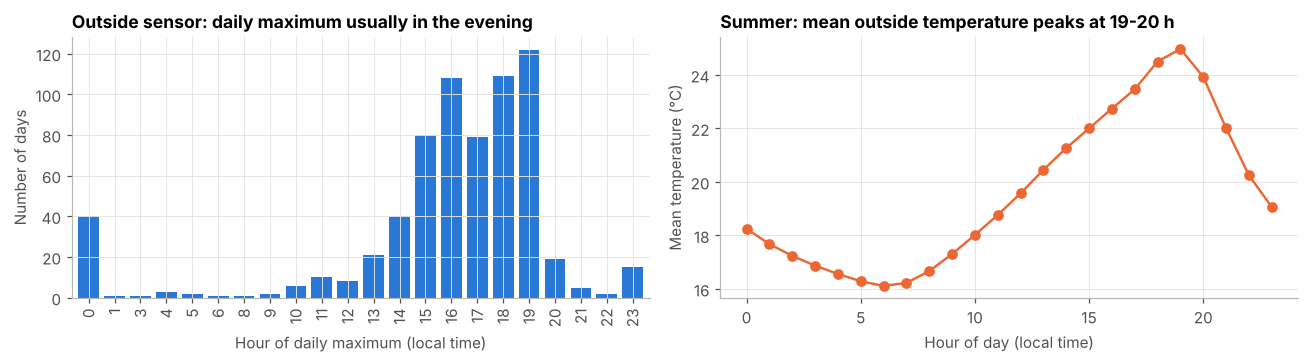

share of days with maximum between 17 and 21 h: 0.495
readings > 32 °C: 304 | of these between 16 and 21 h: 295
top 5 values: {Timestamp('2025-07-01 19:20:00+0200', tz='Europe/Berlin'): 40.44, Timestamp('2025-07-01 19:40:00+0200', tz='Europe/Berlin'): 40.23, Timestamp('2025-07-01 19:00:00+0200', tz='Europe/Berlin'): 39.91, Timestamp('2025-07-01 18:40:00+0200', tz='Europe/Berlin'): 39.46, Timestamp('2025-07-01 20:00:00+0200', tz='Europe/Berlin'): 39.06}


In [11]:
au = df["temp_AU"]
au_ok = au.dropna()
au_day = au_ok.groupby(au_ok.index.date)
daily_max_hour = au_day.idxmax()[au_day.count() >= 60].map(lambda x: x.hour)  # days with >= 20 h of data
summer = au[(au.index.month >= 5) & (au.index.month <= 8)]
hourly = summer.groupby(summer.index.hour).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
daily_max_hour.value_counts().sort_index().plot.bar(ax=axes[0], color=P.SERIES[0], width=0.8)
axes[0].set_title("Outside sensor: daily maximum usually in the evening")
axes[0].set_xlabel("Hour of daily maximum (local time)"); axes[0].set_ylabel("Number of days")
axes[1].plot(hourly.index, hourly, marker="o", color=P.SERIES[1])
axes[1].set_title("Summer: mean outside temperature peaks at 19-20 h")
axes[1].set_xlabel("Hour of day (local time)"); axes[1].set_ylabel("Mean temperature (°C)")
plt.tight_layout(); P.save(fig, "01_sun_outside.png"); plt.show()
print("share of days with maximum between 17 and 21 h:", round(daily_max_hour.between(17, 21).mean(), 3))
print("readings > 32 °C:", int((au > 32).sum()), "| of these between 16 and 21 h:", int(df["flag_sun_AU"].sum()))
print("top 5 values:", au.nlargest(5).round(2).to_dict())
results.update(sun_flag_n=int(df["flag_sun_AU"].sum()), au_max=float(au.max()),
               au_max_evening_share=float(daily_max_hour.between(17, 21).mean()))

**Decision:** the evening peak (instead of the usual afternoon peak) is the signature of
direct evening sun on the west-facing sensor. Readings above 32 °C between 16 and 21 h
are **flagged** (`flag_sun_AU`), not deleted: they are real heat on the facade but do
not represent the air. They are excluded where the outside *air* matters (lag
correlation). Indoor sensors are never above 36 °C except the attic, where 45 °C under a
sun-heated roof is plausible.

### 3f · Short gaps: interpolation of at most 1 hour

Gaps of up to 3 readings (1 h) are filled linearly in time; longer gaps stay `NaN`.
Notebook 02 justifies this limit with the gap length distribution, a hold-out test and
a sensitivity check with limits 2, 3 and 6. Absolute humidity and dew point are
recomputed on filled rows.

In [12]:
interp = clog[clog.step == "interpolate"][["column", "n_values"]]
print(interp.to_string(index=False))
print("share of all sensor values that are interpolated:",
      round(interp.n_values.sum() / df[L.measurement_columns(df)].notna().sum().sum(), 5))

       column  n_values
      temp_AU       314
        rh_AU       314
      temp_O1        50
        rh_O1        50
 surf_temp_O1       480
     temp_AWn        31
       rh_AWn        31
surf_temp_AWn        31
     temp_AWs       137
       rh_AWs       137
surf_temp_AWs       137
     temp_AWo        98
       rh_AWo        98
surf_temp_AWo        98
      temp_K1       286
        rh_K1       286
 surf_temp_K1       352
      temp_K2        77
        rh_K2        77
      temp_D1        48
        rh_D1        48
     temp_Ke1        51
       rh_Ke1        51
share of all sensor values that are interpolated: 0.00228


## 4 · Final assertions and data availability

`final_checks` asserts: unique, sorted, regular 20-minute local-time index; no `-255`
left; relative humidity within 0–100 %; dew point ≤ air temperature; all values in
plausible ranges; flags are boolean. The pipeline fails loudly if any of these break.

all final assertions passed


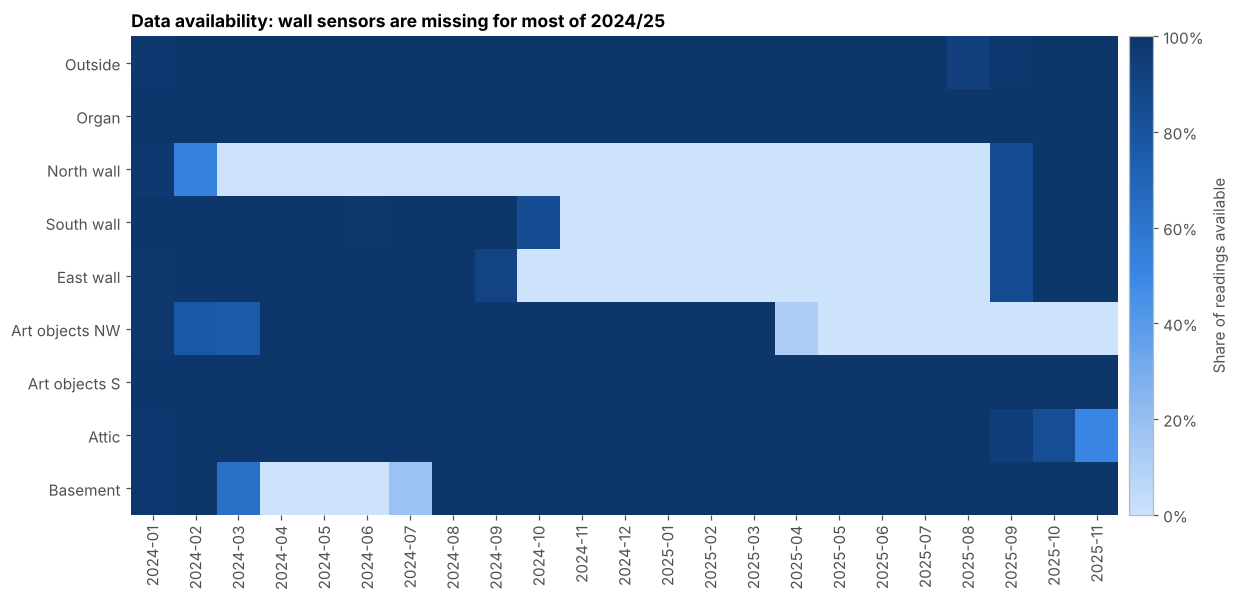

AU     0.995
O1     1.000
AWn    0.166
AWs    0.539
AWo    0.497
K1     0.627
K2     1.000
D1     0.969
Ke1    0.812


In [13]:
L.final_checks(df)
print("all final assertions passed")
temp_cols = [f"temp_{s}" for s in C.SENSORS]
cov = df[temp_cols].notna().groupby(df.index.strftime("%Y-%m")).mean()
cov.columns = [P.name(s) for s in C.SENSORS]
fig, ax = P.calendar_heatmap(cov, "Data availability: wall sensors are missing for most of 2024/25",
                             "Share of readings available", cmap=P.SEQ_BLUE)
P.save(fig, "01_availability.png"); plt.show()
results.save_table(cov.round(3), "availability_by_month")
avail_tot = df[temp_cols].notna().mean().rename(lambda c: c.split("_")[1]).round(3)
print(avail_tot.to_string())
results.update(n_rows_clean=len(df), start=str(df.index.min()), end=str(df.index.max()),
               availability={k: float(v) for k, v in avail_tot.items()},
               n_warmup=int(clog.query("step=='warmup'").n_values.sum()),
               n_interpolated=int(interp.n_values.sum()))

**Key availability facts (decision for all later notebooks):** organ, south art objects
and outside air are almost complete. The north wall only covers Jan–Feb 2024 and
Sep–Nov 2025; the south and east walls have no data from about Oct/Nov 2024 to Sep 2025;
the north-west art objects stop in early April 2025 (only surface temperature continues
from Sep 2025, without humidity); the basement misses Mar–Jul 2024. **No wall sensor
covers the winter 2024/25.** All later comparisons therefore normalise by valid hours
and use common time windows.

## 5 · Save

In [14]:
L.save(df, clog)
print("saved", C.PROCESSED_FILE.relative_to(ROOT), "and", C.CHANGE_LOG_FILE.relative_to(ROOT))
clog[clog.n_values > 0].to_csv(C.TABLE_DIR / "preprocessing_log.csv", index=False)

saved data/processed/clean.parquet and data/processed/preprocessing_log.csv
